# Apply Simple Hill Climbing to a Maze Problem

This notebook demonstrates how hill climbing local search behaves applies to the L-Maze problem.

## Setup

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("L_maze.txt", 
         "https://raw.githubusercontent.com/mhahsler/Introduction_to_Artificial_Intelligence/refs/heads/master/Local_Search/")
download("maze_helper.py", 
         "https://raw.githubusercontent.com/mhahsler/Introduction_to_Artificial_Intelligence/refs/heads/master/Local_Search/")

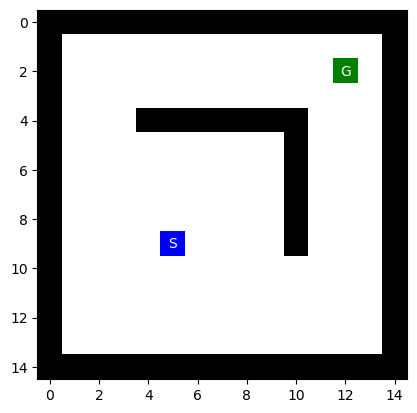

In [2]:
import numpy as np
import maze_helper as mh

f = open("L_maze.txt", "r")

maze_str = f.read()
maze = mh.parse_maze(maze_str)

mh.show_maze(maze)

**Nhận xét bản đồ.** Mê cung L_maze 15×15: `S` (bắt đầu) ở hàng 9, cột 5; `G` (đích) ở hàng 2, cột 12. Giữa hai điểm có một **bức tường chữ L** (hàng 4, cột 4–10 và cột 10, hàng 4–9) nằm chắn ngay trên đường “thẳng” từ S tới G. Đây chính là cái bẫy cực trị cục bộ của bài.

## Search Helper

We need to define an expand function that will produce the neighbors for local search.

In [3]:
DIR2POS = {
    'N' : (-1, 0),
    'E' : ( 0, 1),
    'S' : ( 1, 0),
    'W' : ( 0,-1)
}

ORDER = None
RANDOMIZATION = None
DIRS = None 

# The order matters if RANDOMIZATION = False
# Note that: DFS works takes elements from the frontier in reverse order!
def set_order(order = "NESW", random = False, verbose = True):
    global RANDOMIZATION, DIR2POS, ORDER, DIRS
    
    RANDOMIZATION = random
    ORDER = [pos for pos in order]
    DIRS = [DIR2POS[dir] for dir in ORDER]
    
    if verbose:
        if RANDOMIZATION:
            print("Directions are checked at every step in random order.")
        else:
            print(f"Directions are checked in the order {ORDER}")
        
set_order("NESW", verbose = True)

Directions are checked in the order ['N', 'E', 'S', 'W']


In [4]:
def expand(maze, pos):
    """find available directions as a list of lists with elements [dir, (pos)]."""
    global RANDOMIZATION, DIRS, ORDER
       
    available = [[dir, pos] for dir, pos in zip(ORDER, np.add(pos, DIRS)) if mh.look(maze, pos) != "X"]
    if RANDOMIZATION: np.random.shuffle(available)
        
    return available

**Nhận xét `expand(maze, pos)`.**
- Có 4 hướng `N, E, S, W` với độ dịch `(-1,0), (0,1), (1,0), (0,-1)` theo (hàng, cột).
- Hàm cộng độ dịch vào vị trí hiện tại rồi **loại các ô là tường `X`**; trả về danh sách `[hướng, vị trí]` hợp lệ. Vì mê cung có tường bao quanh nên không bao giờ ra ngoài biên.
- `ORDER` quyết định thứ tự xét hướng (khi `RANDOMIZATION=False`); khi `RANDOMIZATION=True` danh sách láng giềng được xáo trộn mỗi lần gọi. Thứ tự này chỉ ảnh hưởng khi có **hai láng giềng cùng giá trị h** (hòa).
- Trong ô trống/đường thẳng có 4 láng giềng, sát tường chỉ còn 2–3 láng giềng.

# Hill Climbing

We use Manhattan distance to the goal as the objective function (minimization).

In [5]:
# Manhattan distance h(n)
def manhattan(pos1, pos2):
    """returns the Manhattan distance between two positions"""
    return(np.sum(np.abs(np.subtract(pos1, pos2))))
    
print(manhattan([0,0], [1,1]))

2


**Nhận xét `manhattan(pos1, pos2)`.** Hàm mục tiêu $h(n)=|r_n-r_G|+|c_n-c_G|$ (cần **cực tiểu hóa**; giảm $h$ là cải thiện). Đây là heuristic *chỉ dựa trên toạ độ*, **không biết gì về tường** – điều này là nguyên nhân gốc của việc mắc kẹt. Tại S: $h(S)=|9-2|+|5-12|=14$.

In [6]:
def local_search(maze, vis = False, animation = False, verbose = False):
    if animation:
        maze_anim = []
    else:
        maze_anim = None
    
    # Local search starts here
    start_pos = mh.find_pos(maze, "S")
    goal_pos = mh.find_pos(maze, "G")

    current = start_pos
    current_obj = manhattan(current, goal_pos)

    while True:
        # find best neighbor
        neighbors = [n[1] for n in expand(maze, current)]
        obj = [manhattan(n, goal_pos) for n in neighbors]
        best_obj = min(obj)
        best_neighbor = neighbors[obj.index(best_obj)]

        if verbose:
            print("Current state:", current, "with obj", current_obj)
            print("Evaluating neighbors:\t", neighbors)
            print("Obj:\t\t\t", obj)


        # move there if it is an improvement or stop
        if best_obj < current_obj:
            current = best_neighbor
            current_obj = best_obj
            if verbose:
                print("Moving to:", current, "\n")
        else:
            if verbose:
                print("No better state in the neighborhood! Stopping.\n")
            break

        if animation:
            maze2 = maze.copy()
            maze2[current[0], current[1]] = "P"
            maze_anim.append(maze2)


    return { "solution" : current, "path" : None, "reached" : None, "maze_anim" : maze_anim }

**Nhận xét `local_search(...)` (Simple/Greedy Hill Climbing).**
1. Bắt đầu tại `S`, `current_obj = h(S) = 14`.
2. Mỗi vòng: sinh láng giềng bằng `expand`, tính $h$ của từng láng giềng, lấy láng giềng tốt nhất (`min`).
3. Nếu `best_obj < current_obj` thì di chuyển; ngược lại **dừng** (không còn láng giềng nào tốt hơn *một cách nghiêm ngặt*).
4. Chỉ lưu **trạng thái hiện tại** (bộ nhớ O(1)); không có đường đi, không quay lui, không có tập `reached`, nên `path` và `reached` trả về `None`.

Lưu ý: điều kiện dừng dùng `<` chứ không phải `<=`, vì vậy thuật toán cũng dừng ở **plateau** (các láng giềng bằng nhau).

## Run the Algorithm

In [7]:
%time result = local_search(maze, animation = True, verbose = True)
result["solution"]

mh.animate_maze(result)

Current state: (np.int64(9), np.int64(5)) with obj 14
Evaluating neighbors:	 [array([8, 5]), array([9, 6]), array([10,  5]), array([9, 4])]
Obj:			 [np.int64(13), np.int64(13), np.int64(15), np.int64(15)]
Moving to: [8 5] 

Current state: [8 5] with obj 13
Evaluating neighbors:	 [array([7, 5]), array([8, 6]), array([9, 5]), array([8, 4])]
Obj:			 [np.int64(12), np.int64(12), np.int64(14), np.int64(14)]
Moving to: [7 5] 

Current state: [7 5] with obj 12
Evaluating neighbors:	 [array([6, 5]), array([7, 6]), array([8, 5]), array([7, 4])]
Obj:			 [np.int64(11), np.int64(11), np.int64(13), np.int64(13)]
Moving to: [6 5] 

Current state: [6 5] with obj 11
Evaluating neighbors:	 [array([5, 5]), array([6, 6]), array([7, 5]), array([6, 4])]
Obj:			 [np.int64(10), np.int64(10), np.int64(12), np.int64(12)]
Moving to: [5 5] 

Current state: [5 5] with obj 10
Evaluating neighbors:	 [array([5, 6]), array([6, 5]), array([5, 4])]
Obj:			 [np.int64(9), np.int64(11), np.int64(11)]
Moving to: [5 6] 

Cu

**Note:** Simple hill climbing is greedy. It gets stuck in local optima!

## Kết quả chạy và giải thích (Bài 1)

Quan sát chế độ `verbose` ở trên: từ `S=(9,5)` thuật toán đi **N, N, N, N** (lên đến (5,5)), rồi **E, E, E, E** (sang (5,9)) với $h$ giảm đều $14 \to 6$. Tại `(5,9)` các láng giềng hợp lệ chỉ còn `(6,9)` ($h=7$) và `(5,8)` ($h=7$) vì ô phía bắc `(4,9)` và phía đông `(5,10)` là **tường**. Cả hai đều có $h=7 > 6$ nên thuật toán **dừng**.

In [8]:
# Ghi nhận kết quả một cách tường minh
S = tuple(int(x) for x in mh.find_pos(maze, "S"))
G = tuple(int(x) for x in mh.find_pos(maze, "G"))
stop = tuple(int(x) for x in result["solution"])
print("Start S        :", S, " h(S) =", manhattan(S, G))
print("Goal  G        :", G)
print("Điểm dừng      :", stop, " h =", manhattan(stop, G))
print("Đã tới đích?   :", stop == G)
print("Số bước di chuyển:", len(result["maze_anim"]))

Start S        : (9, 5)  h(S) = 14
Goal  G        : (2, 12)
Điểm dừng      : (5, 9)  h = 6
Đã tới đích?   : False
Số bước di chuyển: 8


## Hình minh họa: đường đi Hill Climbing và bản đồ hàm mục tiêu
Hình bên trái: đường đi (ô `P`) và điểm dừng; hình bên phải: giá trị $h(n)$ của từng ô trống – thấy rõ ô `(5,9)` là **cực tiểu cục bộ** ($h=6$) nằm sát bức tường.

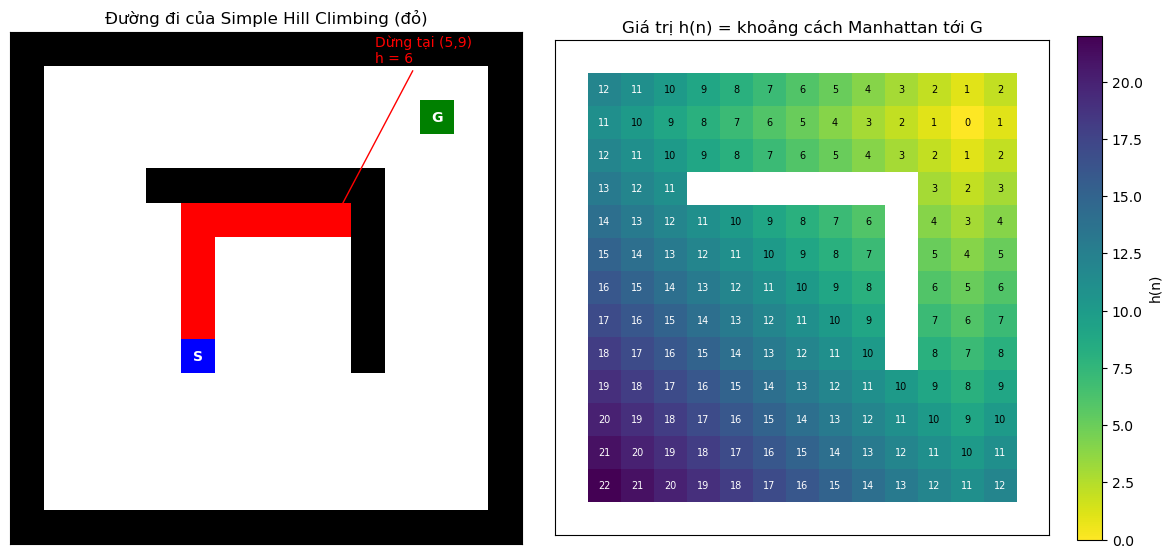

In [9]:
import os
import matplotlib.pyplot as plt
from matplotlib import colors

os.makedirs("figs", exist_ok=True)   # tạo thư mục lưu hình nếu chưa có

set_order("NESW", random=False, verbose=False)
res = local_search(maze, animation=True)
# mỗi khung chỉ chứa ô P hiện tại -> gom tất cả các khung để vẽ đủ đường đi
last = res["maze_anim"][-1].copy()
for m in res["maze_anim"]:
    for p in np.argwhere(m == "P"): last[p[0], p[1]] = "P"

# Hình 1: mê cung + đường đi
disp = mh.maze_to_matrix(last)
cmap = colors.ListedColormap(['white','black','blue','green','red','gray','orange'])
fig, ax = plt.subplots(1, 2, figsize=(12, 5.6))
ax[0].imshow(disp, cmap=cmap, norm=colors.BoundaryNorm(list(range(cmap.N+1)), cmap.N))
ax[0].text(S[1], S[0], "S", color="white", ha="center", va="center", fontweight="bold")
ax[0].text(G[1], G[0], "G", color="white", ha="center", va="center", fontweight="bold")
ax[0].annotate("Dừng tại (5,9)\nh = 6", xy=(9,5), xytext=(10.2,0.4), color="red",
               arrowprops=dict(arrowstyle="->", color="red"), fontsize=10)
ax[0].set_title("Đường đi của Simple Hill Climbing (đỏ)")

# Hình 2: heatmap h(n)
H = np.full(maze.shape, np.nan)
for r in range(maze.shape[0]):
    for c in range(maze.shape[1]):
        if maze[r, c] != "X": H[r, c] = manhattan((r, c), G)
im = ax[1].imshow(H, cmap="viridis_r")
for r in range(H.shape[0]):
    for c in range(H.shape[1]):
        if not np.isnan(H[r, c]): ax[1].text(c, r, int(H[r, c]), ha="center", va="center", fontsize=7, color="white" if H[r,c] > 10 else "black")
ax[1].set_title("Giá trị h(n) = khoảng cách Manhattan tới G")
plt.colorbar(im, ax=ax[1], fraction=0.046, label="h(n)")
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.tight_layout()
plt.savefig("figs/maze_hill_climbing.png", dpi=150)
plt.show()

## Thí nghiệm: đổi thứ tự xét hướng và chọn ngẫu nhiên
Yêu cầu của đề: thay thứ tự xét hướng hoặc lựa chọn ngẫu nhiên (`ORDER`/`RANDOMIZATION`), chạy nhiều lần và nhận xét.

In [10]:
import itertools, collections

def T(p): return tuple(int(x) for x in p)

# (a) Thử cả 24 hoán vị thứ tự hướng (xác định)
fixed = {}
for order in sorted(set("".join(p) for p in itertools.permutations("NESW"))):
    set_order(order, random=False, verbose=False)
    fixed[order] = T(local_search(maze)["solution"])
print("24 thứ tự hướng ->", collections.Counter(fixed.values()))

# (b) Chọn ngẫu nhiên thứ tự hướng, 1000 lần chạy
np.random.seed(42)
set_order("NESW", random=True, verbose=False)
rand = collections.Counter(T(local_search(maze)["solution"]) for _ in range(1000))
print("1000 lần ngẫu nhiên ->", rand)

# (c) Quãng đường tới điểm dừng (số bước) và h cuối
set_order("NESW", random=False, verbose=False)
steps = len(local_search(maze, animation=True)["maze_anim"])
print("Số bước tới điểm dừng:", steps, "| h_cuối =", manhattan(stop, G), "| tỉ lệ tới đích = 0/1024")

24 thứ tự hướng -> Counter({(5, 9): 24})
1000 lần ngẫu nhiên -> Counter({(5, 9): 1000})
Số bước tới điểm dừng: 8 | h_cuối = 6 | tỉ lệ tới đích = 0/1024


### Nhận xét thí nghiệm
- **Cả 24 thứ tự hướng và 1000 lần chạy ngẫu nhiên đều kết thúc tại `(5,9)`** (tỉ lệ tới được `G` = 0%). Lý do: thứ tự/ngẫu nhiên chỉ phá thế hòa giữa các láng giềng cùng $h$ (ví dụ lên hay sang phải đều giảm $h$ đi 1). Mọi “đường đồng giá” như vậy đều dẫn vào cùng một vùng: dưới bức tường chữ L, và cuối cùng chạm tường tại `(5,9)` hoặc các điểm tương đương có $h=6$.
- Nghĩa là **đa dạng hóa việc chọn láng giềng không đủ để thoát khỏi cực trị cục bộ**, vì mọi láng giềng của `(5,9)` đều tệ hơn hoặc bằng nó.
- Cách khắc phục (ngoài phạm vi Simple HC): **Random Restart** từ nhiều điểm xuất phát (bắt đầu ở phía trên tường sẽ tới được G), **Simulated Annealing** (chấp nhận tạm thời bước xấu, đi vòng quanh tường), hoặc dùng tìm kiếm theo đường đi như **A\*** với bộ nhớ đường đi/quay lui.

## Kết luận Bài 1
| Mục | Kết quả |
|---|---|
| Hàm mục tiêu | $h(n)$ = khoảng cách Manhattan tới G (cực tiểu hóa) |
| Xuất phát → đích | S=(9,5) → G=(2,12), $h(S)=14$ |
| `result["solution"]` | **(5, 9)**, $h=6$ |
| Đã tới G? | **Không** – dừng sớm, còn cách đích 6 ô (theo Manhattan) |
| Nguyên nhân | **Cực tiểu cục bộ**: ô (5,9) sát tường, mọi láng giềng hợp lệ có $h=7>6$; heuristic không nhìn thấy tường |
| Ảnh hưởng của thứ tự/ngẫu nhiên | Không thay đổi kết quả (24/24 thứ tự và 1000/1000 lần ngẫu nhiên đều dừng ở (5,9)) |